In [19]:
import scanpy as sc
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import os
import numpy as np

sys.path.append("../../../mapqc/")
import mapqc
import plotting

In [2]:
%load_ext lab_black
%load_ext autoreload
%autoreload 2

In [3]:
sc.set_figure_params(figsize=(5, 5))

## Analysis on default mapping:

In [4]:
dir_results_normal_mapping = "../../../results/HLCA/Sheppard/Sheppard_2020_kl1/"

In [7]:
adata_emb = sc.read_h5ad(
    os.path.join(dir_results_normal_mapping, "combined_embedding_klweight_1.h5ad")
)

In [8]:
mapqc_results_healthy = mapqc.load(
    os.path.join(dir_results_normal_mapping, "mapqc_results_healthy.pkl")
)
mapqc_results_disease = mapqc.load(
    os.path.join(dir_results_normal_mapping, "mapqc_results_disease.pkl")
)

In [7]:
adata_full = sc.read_h5ad(
    "../../../../../../workspace/hlca_lisa.sikkema_malte.luecken/HLCA_reproducibility/data/d10_1101_2022_03_10_483747/HLCA_v1.1_full.h5ad",
    backed="r",
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


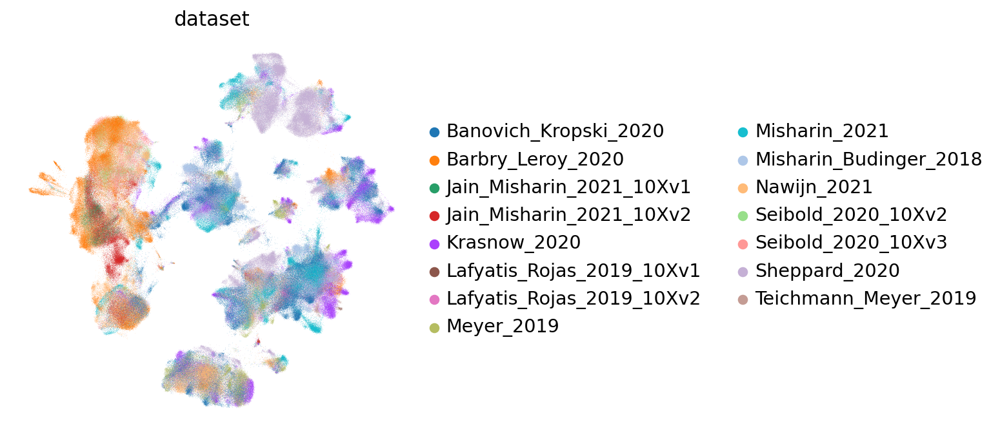

In [8]:
sc.pl.umap(adata_emb, color="dataset", frameon=False)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


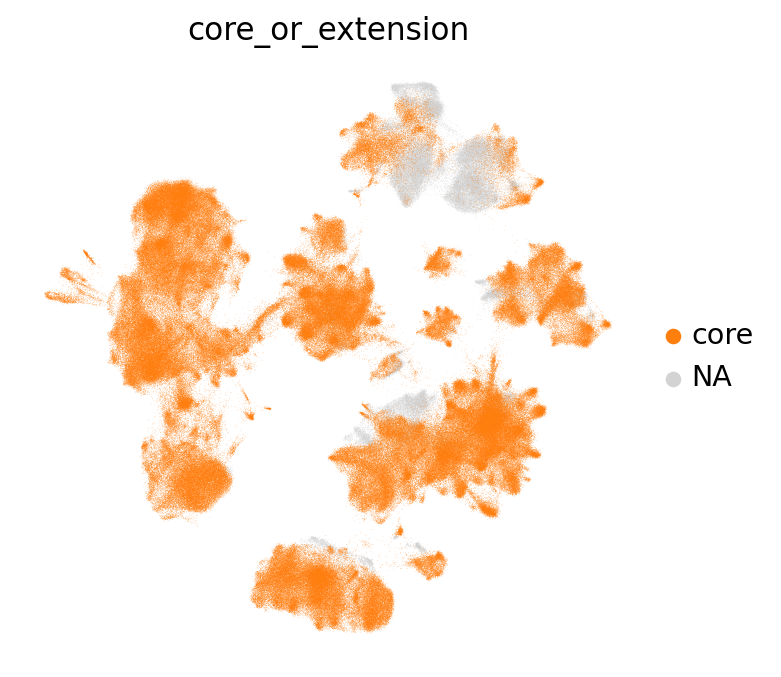

In [9]:
sc.pl.umap(
    adata_emb,
    color="core_or_extension",
    frameon=False,
    palette={"core": "tab:orange", "extension": "tab:blue"},
    groups="core",
)

In [10]:
palette_condition = {
    "reference": "tab:orange",
    "NML": "maroon",
    "IPF": "c",
    "SCD": "dodgerblue",
}

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


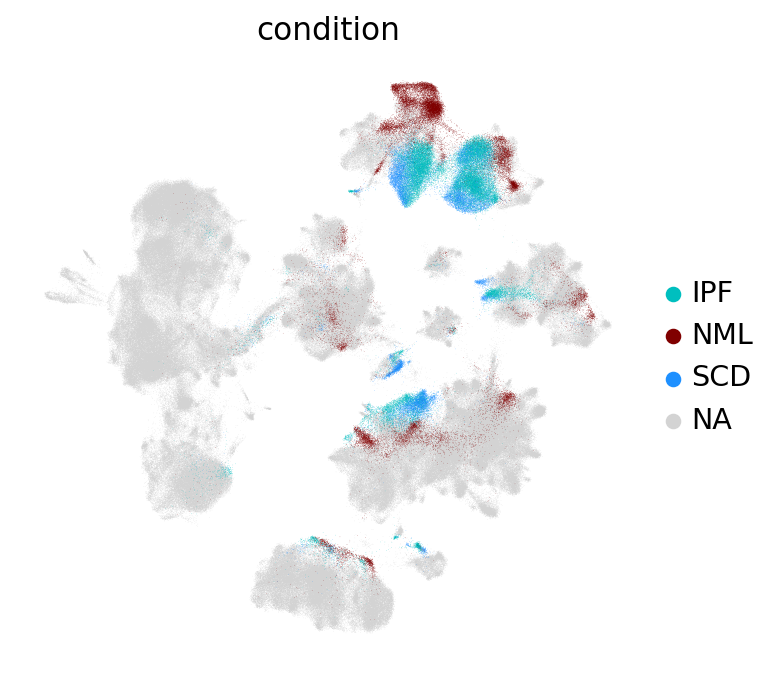

In [11]:
sc.pl.umap(
    adata_emb,
    color="condition",
    frameon=False,
    palette=palette_condition,
    groups=["IPF", "NML", "SCD"],
)

In [12]:
# sc.tl.leiden(adata_emb)

load leiden clustering from previous run:

In [13]:
clustering_df = pd.read_csv("./leiden_res_1_kl1_per_dataset.csv", index_col=0)

In [14]:
adata_emb.obs["leiden"] = pd.Categorical(
    clustering_df.loc[adata_emb.obs.index, "leiden"]
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


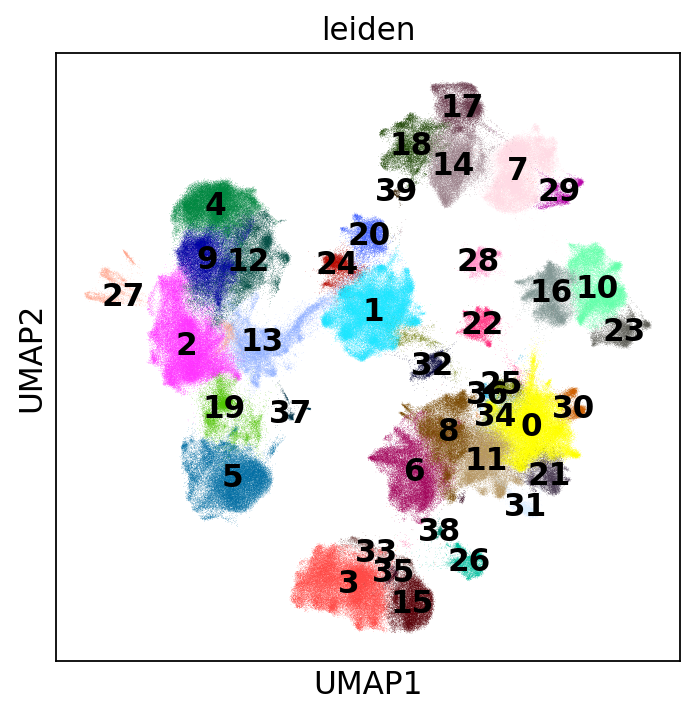

In [15]:
sc.pl.umap(adata_emb, color="leiden", legend_loc="on data")

In [11]:
for stat in [
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    "mapqc_per_cell_mean_zscored_dist_to_ref>2_sample_based",
]:
    adata_emb.obs[stat] = np.nan
    healthy_idc = [
        idx
        for idx in adata_emb.obs.index
        if idx in mapqc_results_healthy.adata.obs.index
    ]
    adata_emb.obs.loc[healthy_idc, stat] = mapqc_results_healthy.adata.obs.loc[
        healthy_idc, stat
    ]
    disease_idc = [
        idx
        for idx in adata_emb.obs.index
        if idx in mapqc_results_disease.adata.obs.index
    ]
    adata_emb.obs.loc[disease_idc, stat] = mapqc_results_disease.adata.obs.loc[
        disease_idc, stat
    ]

perform label transfer (TO DO: move this to emb preparation script later):

In [12]:
import label_transfer

In [13]:
knn_trainer = label_transfer.weighted_knn_trainer(
    train_adata=adata_emb[adata_emb.obs.core_or_extension == "core", :],
    train_adata_emb="X",
)

Weighted KNN with n_neighbors = 50 ... 

In [14]:
(
    transfered_labels_lev2,
    transfer_uncertainties_lev2,
) = label_transfer.weighted_knn_transfer(
    query_adata=adata_emb[adata_emb.obs.core_or_extension == "extension", :],
    query_adata_emb="X",
    ref_adata_obs=adata_emb[adata_emb.obs.core_or_extension == "core", :].obs,
    label_keys="ann_level_2",
    knn_model=knn_trainer,
)

finished!


In [15]:
(
    transfered_labels_lev3,
    transfer_uncertainties_lev3,
) = label_transfer.weighted_knn_transfer(
    query_adata=adata_emb[adata_emb.obs.core_or_extension == "extension", :],
    query_adata_emb="X",
    ref_adata_obs=adata_emb[adata_emb.obs.core_or_extension == "core", :].obs,
    label_keys="ann_level_3",
    knn_model=knn_trainer,
)

finished!


In [16]:
# lev 2
adata_emb.obs["ann_level_2_transf"] = adata_emb.obs["ann_level_2"].values
adata_emb.obs.loc[
    transfered_labels_lev2.index, "ann_level_2_transf"
] = transfered_labels_lev2.values
adata_emb.obs.ann_level_2_transf = adata_emb.obs.ann_level_2_transf.tolist()
adata_emb.obs["ann_level_2_transf_uncert"] = np.nan
adata_emb.obs.loc[
    transfer_uncertainties_lev2.index, "ann_level_2_transf_uncert"
] = transfer_uncertainties_lev2.values
# lev 3
adata_emb.obs["ann_level_3_transf"] = adata_emb.obs["ann_level_3"].values
adata_emb.obs.loc[
    transfered_labels_lev3.index, "ann_level_3_transf"
] = transfered_labels_lev3.values
adata_emb.obs.ann_level_3_transf = adata_emb.obs.ann_level_3_transf.tolist()
adata_emb.obs["ann_level_3_transf_uncert"] = np.nan
adata_emb.obs.loc[
    transfer_uncertainties_lev3.index, "ann_level_3_transf_uncert"
] = transfer_uncertainties_lev3.values

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


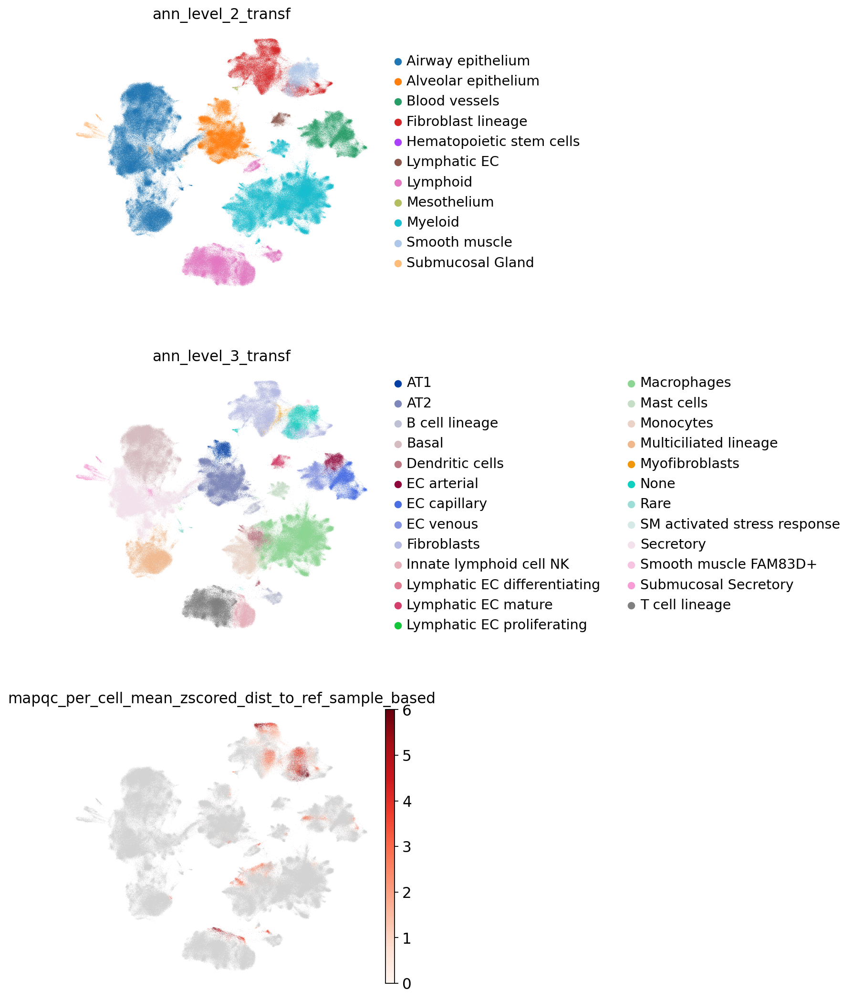

In [17]:
sc.pl.umap(
    adata_emb,
    color=[
        "ann_level_2_transf",
        "ann_level_3_transf",
        "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    ],
    frameon=False,
    ncols=1,
    vmin=0,
    vmax=6,
    cmap="Reds",
)

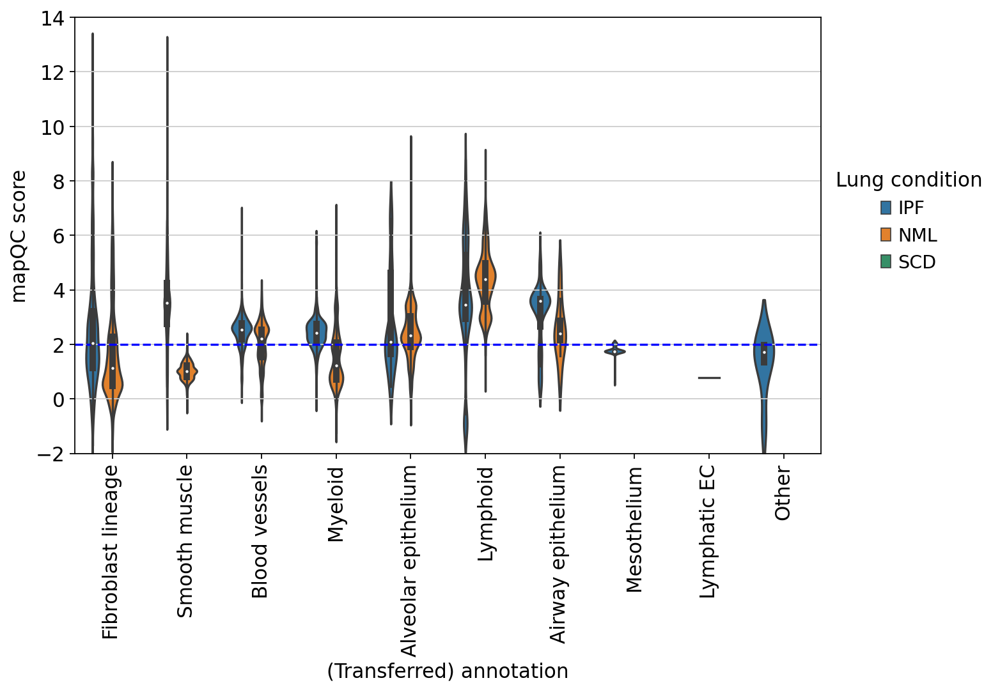

In [24]:
fig, ax = plt.subplots(figsize=(10, 7))
obs_to_plot = adata_emb.obs.loc[
    adata_emb.obs.core_or_extension == "extension",
    [
        "ann_level_2_transf",
        "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
        "condition",
    ],
]
obs_to_plot.ann_level_2_transf = obs_to_plot.ann_level_2_transf.tolist()
# remove low-frequency groups. First identify the groups:
min_n_cells = 50
ct_count_per_condition = pd.crosstab(
    obs_to_plot.ann_level_2_transf, obs_to_plot.condition
)
groups_to_remove_tumor = ct_count_per_condition.loc[
    ct_count_per_condition.IPF < min_n_cells, :
].index.tolist()
groups_to_remove_healthy = ct_count_per_condition.loc[
    ct_count_per_condition.NML < min_n_cells, :
].index.tolist()
# then set them to "Other"
obs_to_plot.loc[
    (obs_to_plot.condition == "IPF")
    & (obs_to_plot.ann_level_2_transf.isin(groups_to_remove_tumor)),
    "ann_level_2_transf",
] = "Other"
obs_to_plot.loc[
    (obs_to_plot.condition == "NML")
    & (obs_to_plot.ann_level_2_transf.isin(groups_to_remove_healthy)),
    "ann_level_2_transf",
] = "Other"
# set mapqc scores to float
obs_to_plot["mapqc_per_cell_mean_zscored_dist_to_ref_sample_based"] = obs_to_plot[
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based"
].astype(float)
# plot
sns.violinplot(
    obs_to_plot,
    x="ann_level_2_transf",
    y="mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    hue="condition",
)
ax.tick_params(axis="x", rotation=90)
plt.axhline(y=2, xmin=0, xmax=10, linestyle="--", color="blue")
plt.legend(loc=(1.01, 0.4), frameon=False, title="Lung condition")
plt.ylim((-2, 14))
plt.xlabel("(Transferred) annotation")
plt.ylabel("mapQC score")
plt.tight_layout()

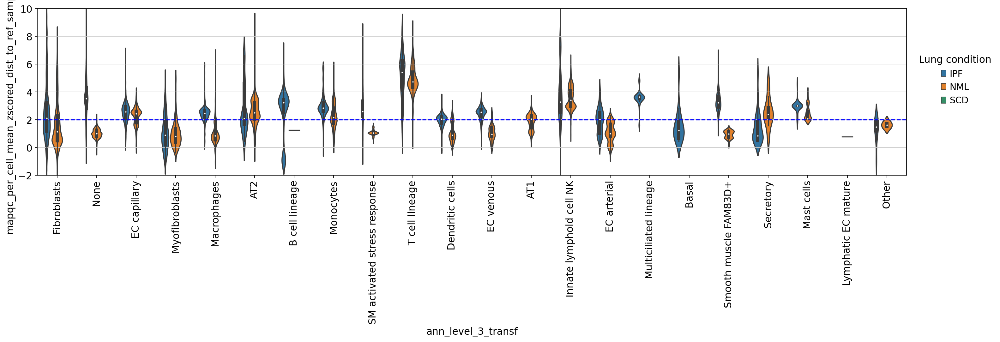

In [21]:
fig, ax = plt.subplots(figsize=(20, 7))
obs_to_plot = adata_emb.obs.loc[
    adata_emb.obs.core_or_extension == "extension",
    [
        "ann_level_3_transf",
        "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
        "condition",
    ],
]
obs_to_plot.ann_level_3_transf = obs_to_plot.ann_level_3_transf.tolist()
# remove low-frequency groups. First identify the groups:
min_n_cells = 50
ct_count_per_condition = pd.crosstab(
    obs_to_plot.ann_level_3_transf, obs_to_plot.condition
)
groups_to_remove_tumor = ct_count_per_condition.loc[
    ct_count_per_condition.IPF < min_n_cells, :
].index.tolist()
groups_to_remove_healthy = ct_count_per_condition.loc[
    ct_count_per_condition.NML < min_n_cells, :
].index.tolist()
# then set them to "Other"
obs_to_plot.loc[
    (obs_to_plot.condition == "IPF")
    & (obs_to_plot.ann_level_3_transf.isin(groups_to_remove_tumor)),
    "ann_level_3_transf",
] = "Other"
obs_to_plot.loc[
    (obs_to_plot.condition == "NML")
    & (obs_to_plot.ann_level_3_transf.isin(groups_to_remove_healthy)),
    "ann_level_3_transf",
] = "Other"
# set mapqc scores to float
obs_to_plot["mapqc_per_cell_mean_zscored_dist_to_ref_sample_based"] = obs_to_plot[
    "mapqc_per_cell_mean_zscored_dist_to_ref_sample_based"
].astype(float)
# plot
sns.violinplot(
    obs_to_plot,
    x="ann_level_3_transf",
    y="mapqc_per_cell_mean_zscored_dist_to_ref_sample_based",
    hue="condition",
)
ax.tick_params(axis="x", rotation=90)
plt.axhline(y=2, xmin=0, xmax=10, linestyle="--", color="blue")
plt.legend(loc=(1.01, 0.4), frameon=False, title="Lung condition")
plt.ylim((-2, 10))
plt.tight_layout()

In [16]:
adata_emb.obs.condition = adata_emb.obs.condition.tolist()
adata_emb.obs.condition = adata_emb.obs.condition.fillna(value="reference")

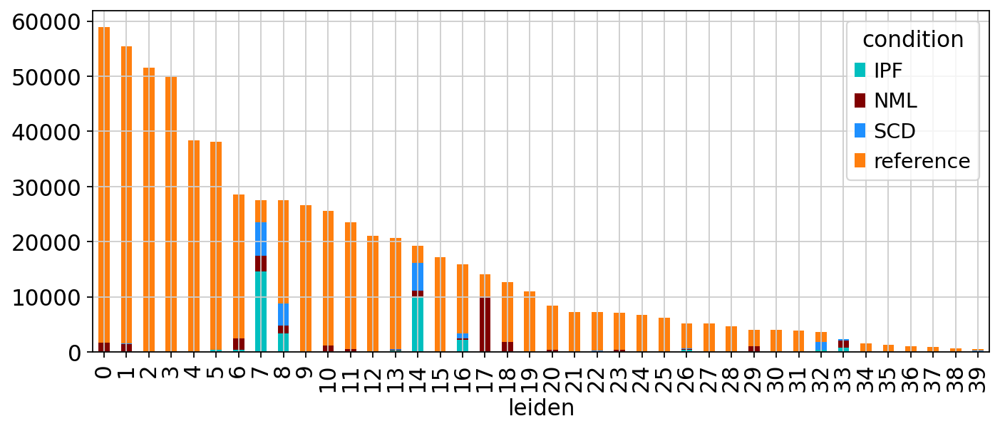

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
pd.crosstab(adata_emb.obs.leiden, adata_emb.obs.condition).plot(
    kind="bar", stacked=True, ax=ax, color=palette_condition
)
plt.tight_layout()

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


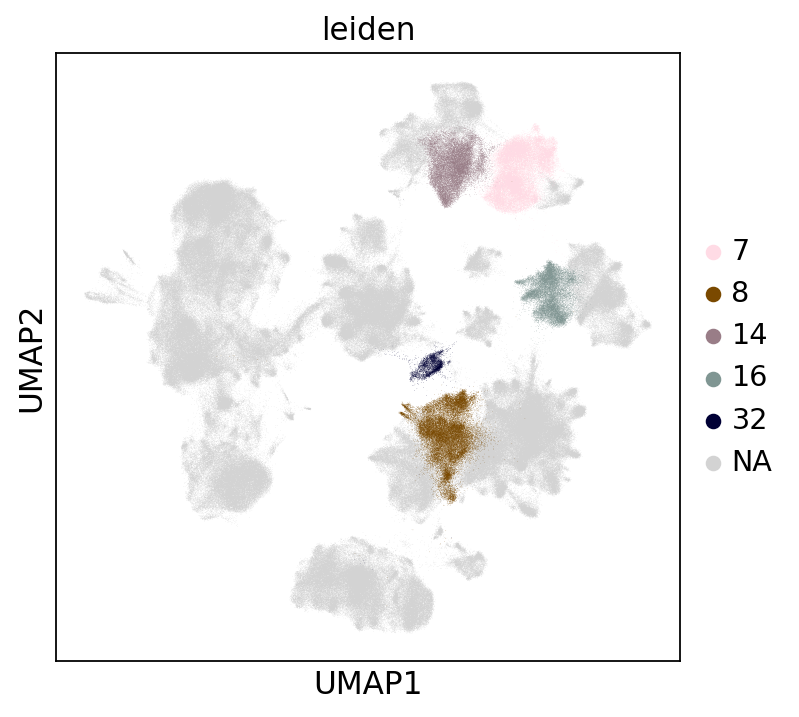

In [18]:
sc.pl.umap(adata_emb, color="leiden", groups=[7, 8, 14, 16, 32])

In [19]:
adata_emb_cl16 = adata_emb[adata_emb.obs.leiden.isin([16, 10, 23]), :].copy()

In [20]:
adata_emb_cl16.shape

(48614, 30)

In [21]:
sc.pp.neighbors(adata_emb_cl16, n_neighbors=30)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_o

In [22]:
sc.tl.umap(adata_emb_cl16)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


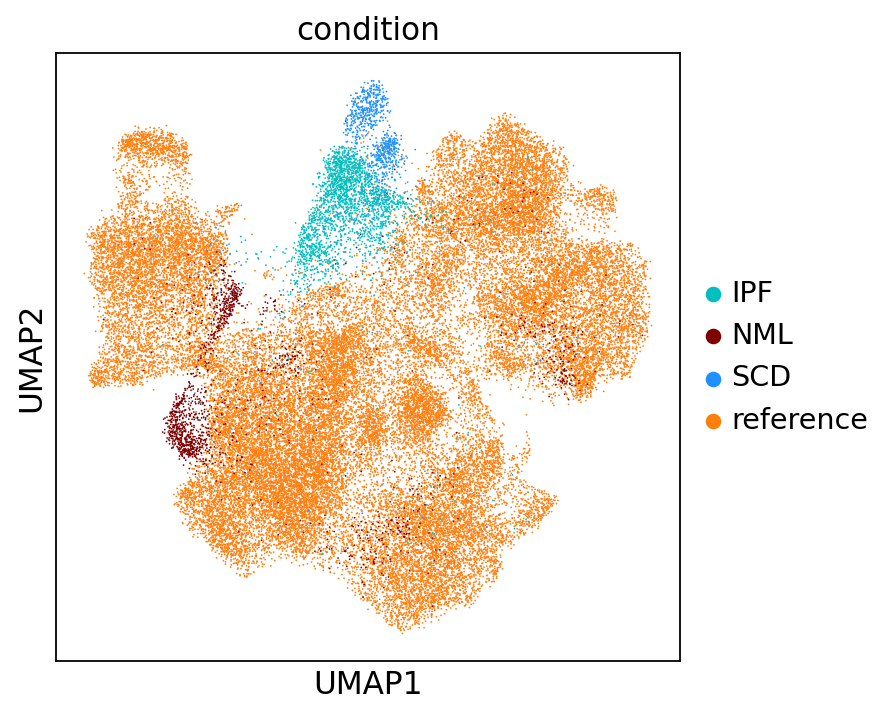

In [23]:
sc.pl.umap(adata_emb_cl16, color="condition", palette=palette_condition)

In [24]:
sc.tl.leiden(adata_emb_cl16, resolution=0.2)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


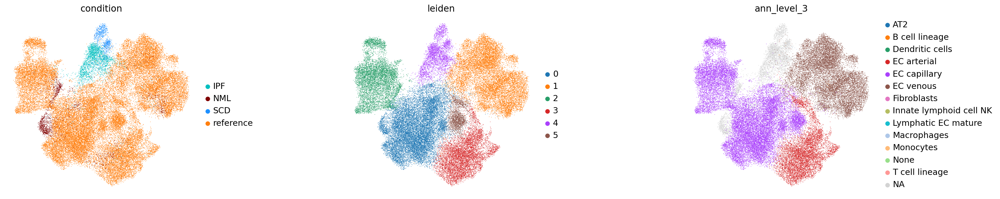

In [25]:
sc.pl.umap(
    adata_emb_cl16,
    color=["condition", "leiden", "ann_level_3"],
    wspace=0.6,
    frameon=False,
)

/tmp/ipykernel_3684798/867632577.py:9: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


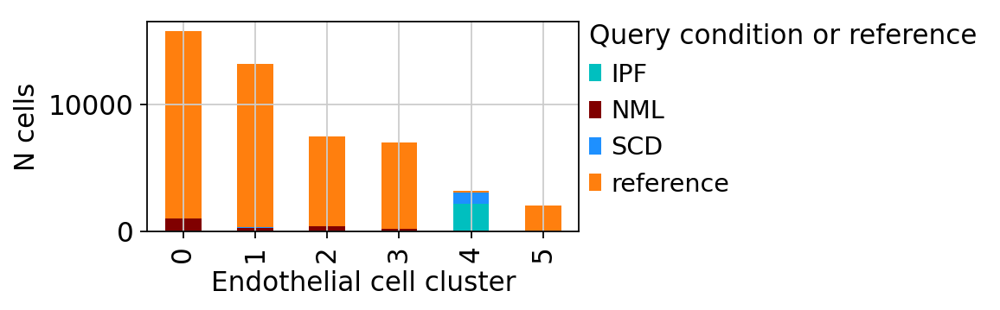

In [26]:
fig, ax = plt.subplots(figsize=(4, 2))
pd.crosstab(adata_emb_cl16.obs.leiden, adata_emb_cl16.obs.condition).plot(
    kind="bar", stacked="true", color=palette_condition, ax=ax
)
ax.set_ylabel("N cells")
ax.set_xlabel("Endothelial cell cluster")
leg = plt.legend(loc=(1.0, 0.12), frameon=False, title="Query condition or reference")
leg._legend_box.align = "left"
plt.tight_layout()

add tsukui suffix to Sheppard_2020 cells, so that barcodes correspond to barcodes in full HLCA:

In [28]:
adata_emb_cl16.obs.index = [
    idx if dataset != "Sheppard_2020" else f"{idx}_tsukui"
    for idx, dataset in zip(adata_emb_cl16.obs.index, adata_emb_cl16.obs.dataset)
]

In [29]:
adata_cl16 = adata_full[
    adata_full.obs.index.isin(adata_emb_cl16.obs.index), :
].to_memory()

In [30]:
adata_cl16.shape

(48614, 59586)

In [31]:
sc.pp.filter_genes(adata_cl16, min_cells=5)

In [32]:
adata_cl16.shape

(48614, 21489)

In [33]:
adata_cl16.X[:10, :10].toarray()

array([[0.       , 0.       , 1.6584647, 0.       , 0.       , 0.       ,
        1.6584647, 0.       , 0.       , 0.       ],
       [0.       , 0.       , 2.7450175, 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 1.9220252, 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 1.4388765, 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 1.9718474, 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 4.468745 , 0.       , 0.       , 0.       ,
        0.       , 1.9095148, 0.       , 0.       ],
       [0.       , 0.       , 0.       , 0.       , 0.       , 0.       ,
        0.       , 0.       , 0.       , 0.       ],
       [0.       , 0.       , 1.0560739, 0.       , 0.       , 0.       ,
        1.0560739, 0.       , 0.     

In [34]:
adata_cl16.uns["log1p"]["base"] = None

In [35]:
adata_cl16.obsm["X_umap"] = adata_emb_cl16[adata_cl16.obs.index, :].obsm["X_umap"]

In [36]:
adata_cl16.obs["condition"] = adata_emb_cl16.obs.loc[adata_cl16.obs.index, "condition"]
adata_cl16.obs["leiden"] = adata_emb_cl16.obs.loc[adata_cl16.obs.index, "leiden"]

In [37]:
adata_cl16.obs.condition.value_counts()

reference    43687
IPF           2309
NML           1656
SCD            962
Name: condition, dtype: int64

In [38]:
adata_cl16.var.index = adata_cl16.var.gene_symbol

In [39]:
sc.tl.rank_genes_groups(adata_cl16, groupby="leiden")

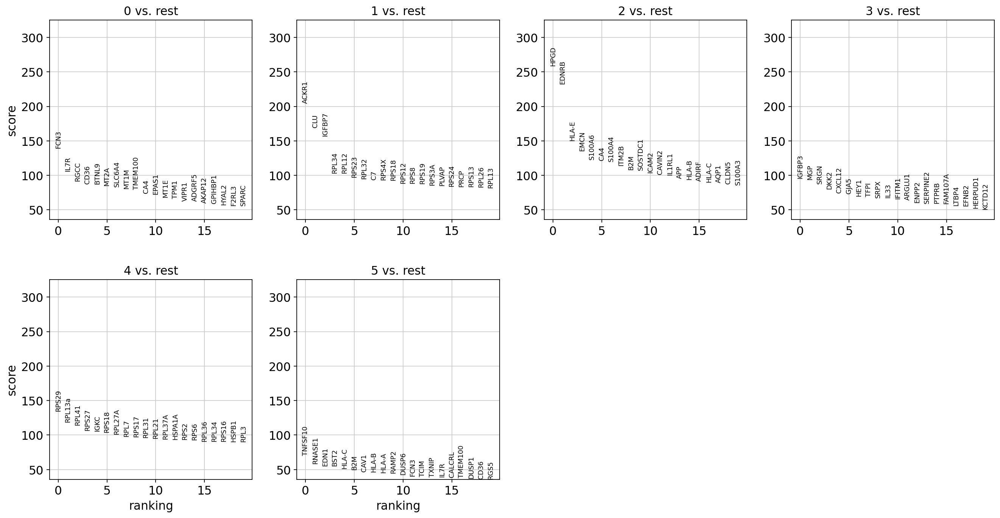

In [40]:
sc.pl.rank_genes_groups(adata_cl16)

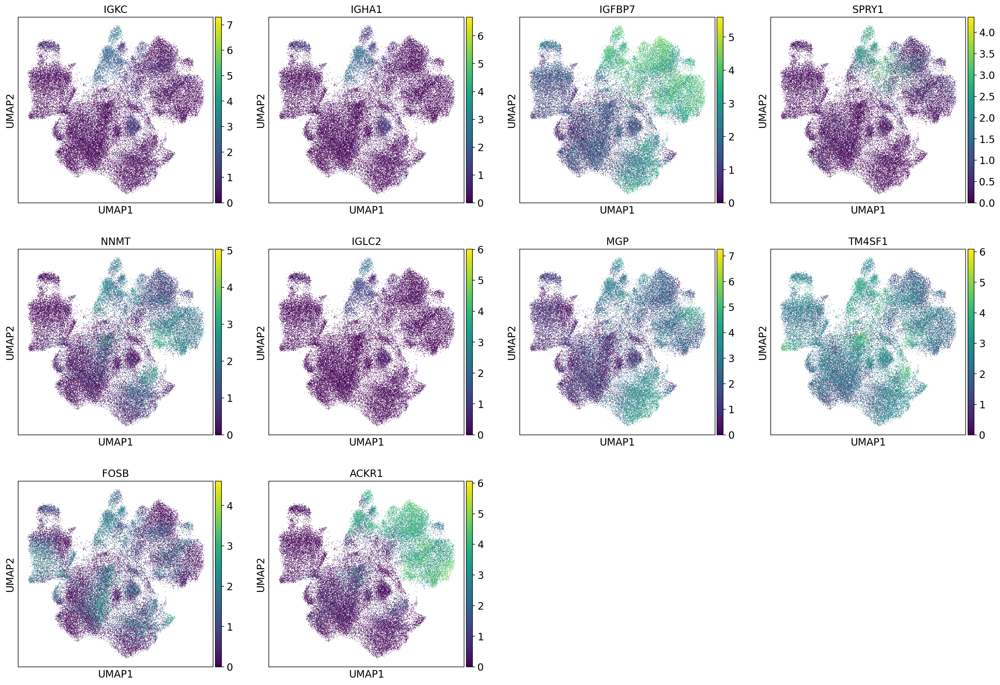

In [41]:
sc.pl.umap(
    adata_cl16,
    color=[
        "IGKC",
        "IGHA1",
        "IGFBP7",
        "SPRY1",
        "NNMT",
        "IGLC2",
        "MGP",
        "TM4SF1",
        "FOSB",
        "ACKR1",
    ],
)

In [43]:
degs_disease_cluster = sc.get.rank_genes_groups_df(adata_cl16, group="4")

In [44]:
gene_ids_used_during_mapping = pd.read_csv(
    "../remappings/HLCA_reference_model/var_names.csv", index_col=0
)

In [45]:
genes_in_data_used_during_mapping = adata_cl16.var.loc[
    adata_cl16.var.ensembl_id.isin(gene_ids_used_during_mapping.index), :
].index.tolist()

In [46]:
degs_disease_cluster.loc[
    degs_disease_cluster.names.isin(genes_in_data_used_during_mapping), :
].head(10)

,names,scores,logfoldchanges,pvals,pvals_adj
4,IGKC,105.830551,5.416986,0.0,0.0
31,IGHA1,80.636200,5.434505,0.0,0.0
54,IGFBP7,67.092552,2.094918,0.0,0.0
58,SPRY1,65.933258,3.963631,0.0,0.0
63,NNMT,63.298412,2.333945,0.0,0.0
77,IGLC2,57.239594,5.406235,0.0,0.0
85,MGP,52.947708,1.918920,0.0,0.0
91,TM4SF1,49.052357,1.292214,0.0,0.0
95,FOSB,48.087593,1.879645,0.0,0.0
97,ACKR1,46.976223,2.365191,0.0,0.0


notes: IGKC: plasma cells, IGHA1: plasma and B cells, 

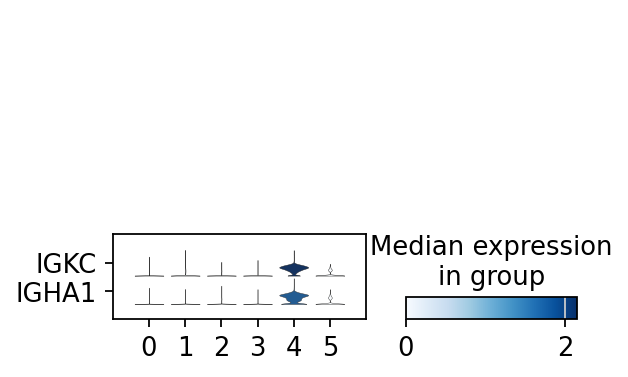

In [47]:
sc.pl.stacked_violin(
    adata_cl16,
    groupby="leiden",
    var_names=[
        "IGKC",
        "IGHA1",
    ],
    swap_axes=True,
)

In [ ]:
sc.pl.stacked_violin(
    adata_cl16,
    groupby="leiden",
    var_names=[
        "IGKC",
        "IGHA1",
        "IGFBP7",
        "SPRY1",
        "NNMT",
        "IGLC2",
        "MGP",
        "TM4SF1",
        "FOSB",
        "ACKR1",
    ],
    swap_axes=True,
)

In [ ]:
sc.pl.umap(adata_full,color=[adata_cl16.var.loc[gene_name, 'ensembl_id'] for gene_name in ["IGKC","IGHA1","RPS29"]])

In [ ]:
sc.pl.umap(adata_full, color='ann_level_2')

In [10]:
mapqc_results_healthy._adata_prepped_for_cell_level_res_plotting_sample_based = False
mapqc_results_healthy._adata_prepped_for_cell_level_res_plotting_nhood_only_based = (
    False
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


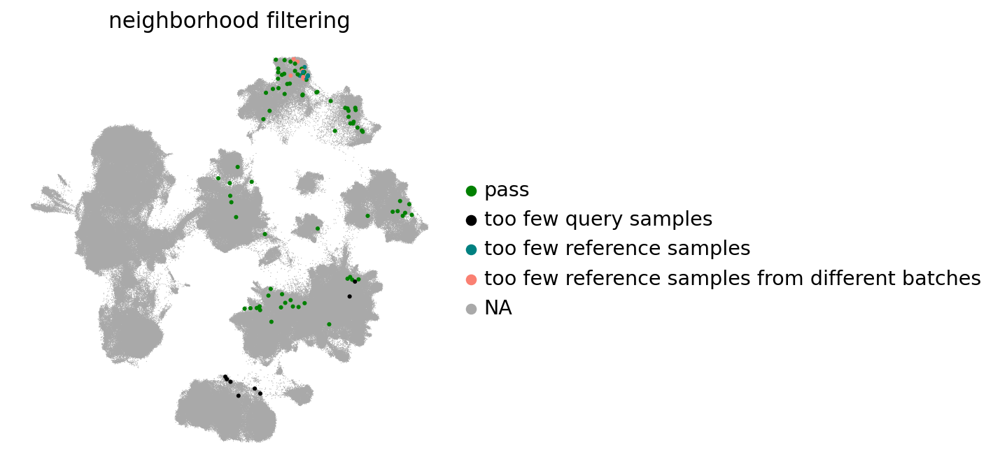

In [14]:
plotting.plot_umap_filtering_info(mapqc_results_healthy)

In [16]:
mapqc_results_disease.min_n_samples_q

1

In [15]:
mapqc_results_healthy.min_n_samples_q

3

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


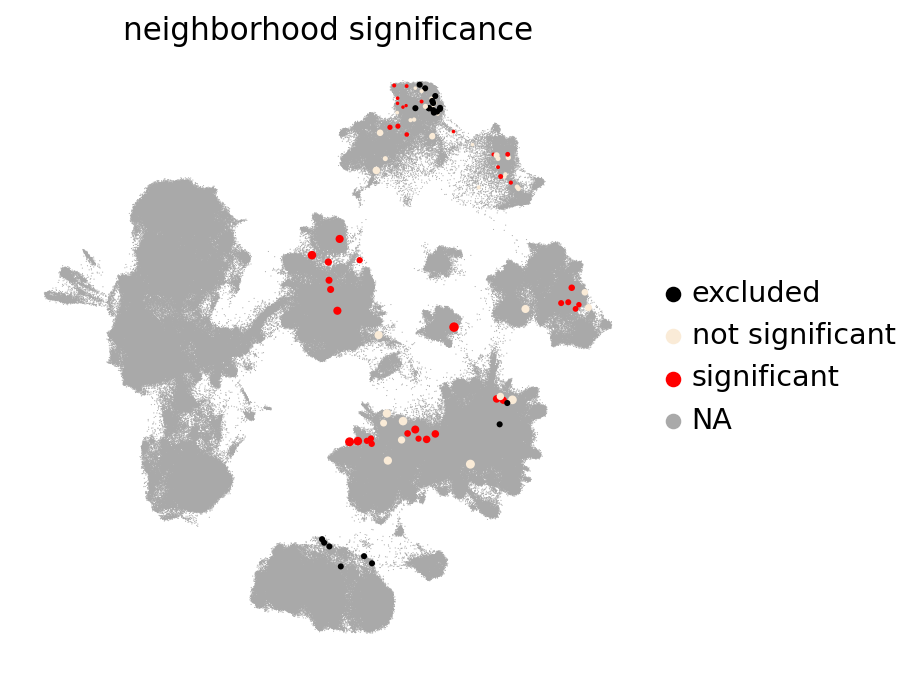

In [13]:
plotting.plot_umap_significance(mapqc_results_healthy)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


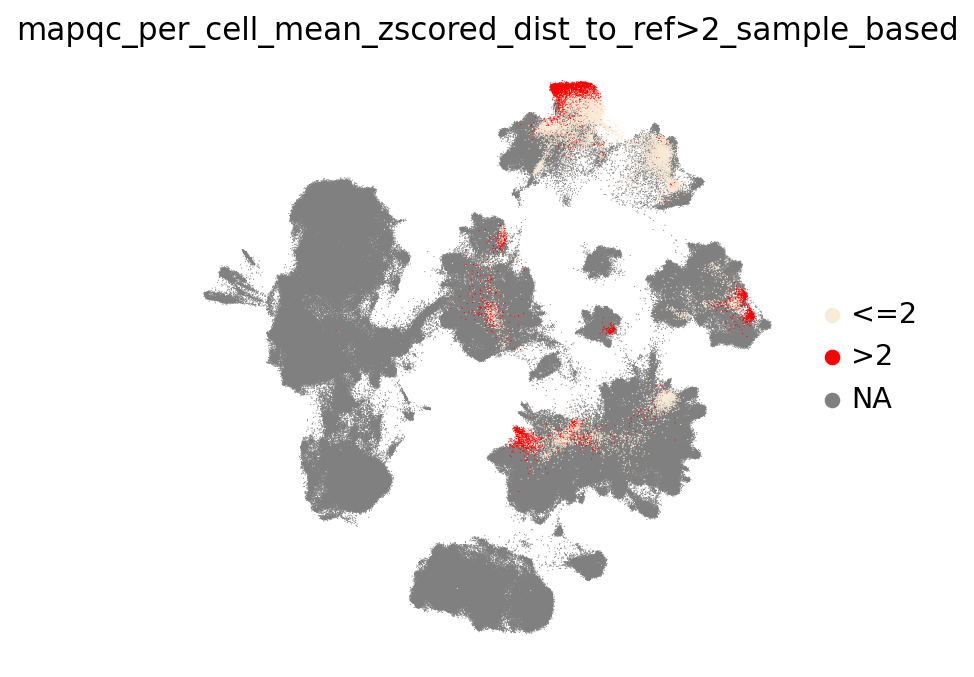

In [11]:
plotting.plot_umap_cell_level_results(
    mapqc_results_healthy, color_by="zscore>2", size=1
)

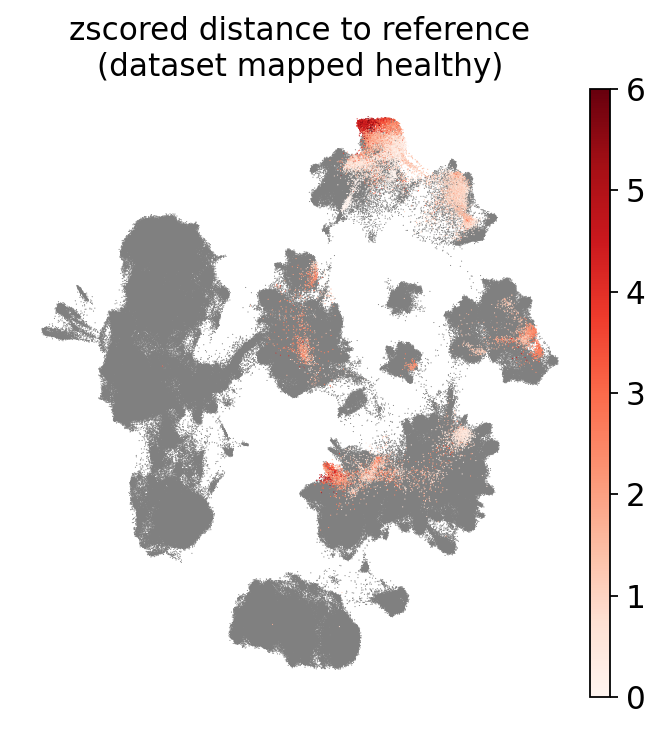

In [12]:
plotting.plot_umap_cell_level_results(
    mapqc_results_healthy,
    color_by="zscore",
    size=1,
    vmin=0,
    vmax=6,
    title="zscored distance to reference\n(dataset mapped healthy)",
)

In [7]:
mapqc_results_disease._adata_prepped_for_cell_level_res_plotting_sample_based = False
mapqc_results_disease._adata_prepped_for_cell_level_res_plotting_nhood_only_based = (
    False
)

/home/icb/lisa.sikkema/miniconda3/envs/mapqc_ot/lib/python3.9/site-packages/scanpy/plotting/_tools/scatterplots.py:392: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


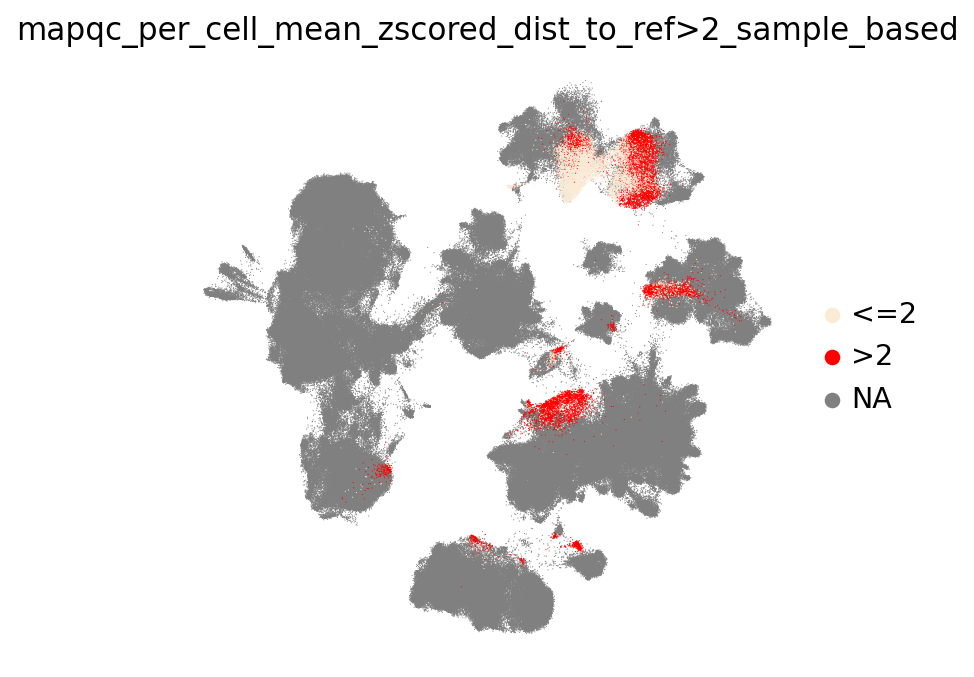

In [8]:
plotting.plot_umap_cell_level_results(
    mapqc_results_disease, color_by="zscore>2", size=1
)

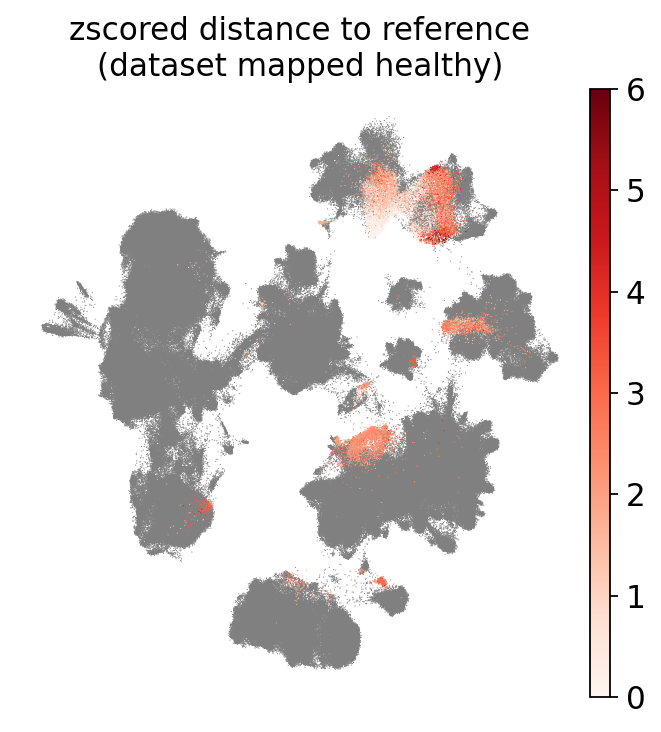

In [9]:
plotting.plot_umap_cell_level_results(
    mapqc_results_disease,
    color_by="zscore",
    size=1,
    vmin=0,
    vmax=6,
    title="zscored distance to reference\n(dataset mapped healthy)",
)